# Inside a Decision Tree, and Inside a Random Forest: Iris Flowers

In Example 1 we used decision trees and random forests to make predictions. In this example we **open them up and look inside**. We will:

* see exactly how scikit-learn **stores** a decision tree in the computer,
* **follow individual flowers** down the tree, question by question, to see how each prediction is made, and
* discover that a random forest is nothing more than a **list of these same trees** that vote, and then build one ourselves, step by step.

**Roadmap**

| Part | What we do |
|---|---|
| 0 | Meet the iris data |
| 1 | Train and draw a small decision tree |
| 2 | Open the tree: how it is stored as arrays of numbers |
| 3 | Follow individual flowers through the tree |
| 4 | See the weaknesses of a single tree |
| 5 | Build a random forest by hand, step by step |
| 6 | Use scikit-learn's random forest and look inside it |
| 7 | Compare the models side by side |

> **How to use this notebook:** run the cells from top to bottom (Shift + Enter). Read the text above each code cell before you run it, and try to predict what will happen.

## Part 0: The Iris Data

The iris dataset is one of the most famous datasets in statistics. It was collected in the 1930s and contains measurements of **150 iris flowers**, 50 from each of three species:

| Class number | Species |
|---|---|
| 0 | *setosa* |
| 1 | *versicolor* |
| 2 | *virginica* |

For each flower, four measurements were taken, all in centimeters:

| Column | Meaning |
|---|---|
| sepal length, sepal width | The **sepals** are the green, leaf-like parts underneath the petals that protect the flower bud |
| petal length, petal width | The **petals** are the colorful parts of the flower |

Our goal: **given the four measurements of a flower, predict its species.**

The dataset comes built into scikit-learn, so there is nothing to download. First we import the tools we need.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

In [2]:
iris = load_iris()

`iris` is a bundle that holds several things. The most important ones are:

* `iris.data`: a table of numbers with one row per flower and one column per measurement,
* `iris.target`: the species of each flower, stored as a number (0, 1, or 2),
* `iris.feature_names` and `iris.target_names`: the names that go with those columns and numbers.

In [3]:
print("Feature names:", iris.feature_names)
print("Species names:", [str(name) for name in iris.target_names])
print("Shape of the data (flowers, measurements):", iris.data.shape)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Species names: ['setosa', 'versicolor', 'virginica']
Shape of the data (flowers, measurements): (150, 4)


The raw numbers are easier to read in a pandas DataFrame, so let's put them in one just for viewing:

In [4]:
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df['species'] = [iris.target_names[t] for t in iris.target]
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
iris_df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

All three species have exactly 50 flowers. That means a "model" that always guesses the same species would only be right **1 time in 3 (33%)**. That is our **baseline**; a useful model must do much better.

### Which measurements tell the species apart?

The grid below plots every pair of measurements against each other. Each dot is one flower, colored by species. The diagonal shows a histogram of each single measurement.

**What to look for:** pairs where the three colors form separate clumps are the most useful for telling species apart. Which measurements separate the species best? Which species is easiest to recognize?

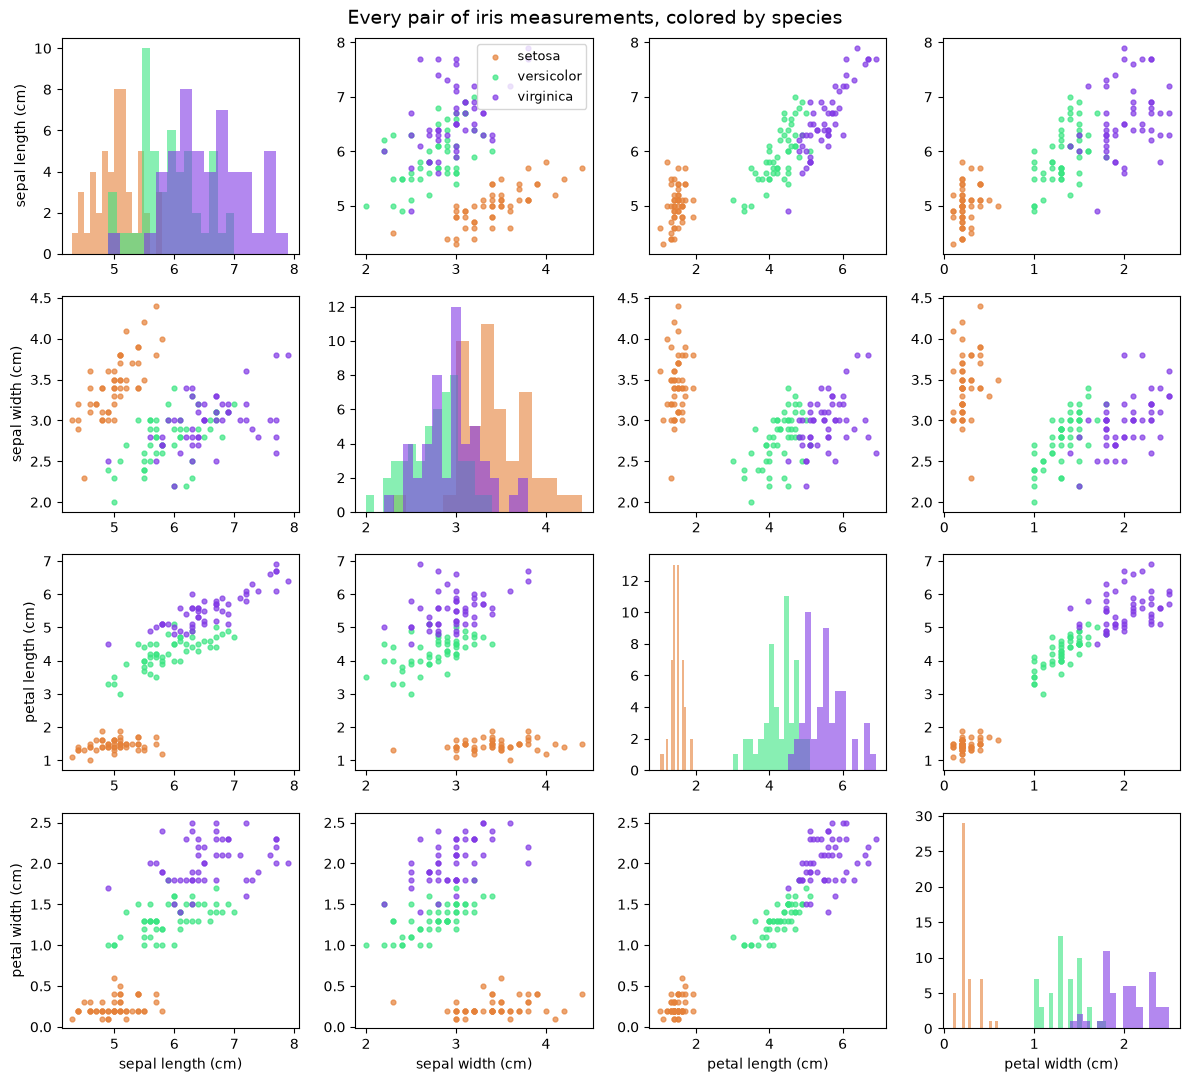

In [6]:
# colors for the three species (the same colors scikit-learn uses when it draws a tree)
SPECIES_COLORS = ['#e58139', '#39e581', '#8139e5']   # setosa, versicolor, virginica

names = iris.feature_names
fig, axes = plt.subplots(4, 4, figsize=(12, 11))
for row in range(4):
    for col in range(4):
        ax = axes[row, col]
        for k, species in enumerate(iris.target_names):
            data_k = iris.data[iris.target == k]
            if row == col:
                ax.hist(data_k[:, col], bins=15, alpha=0.6, color=SPECIES_COLORS[k])
            else:
                ax.scatter(data_k[:, col], data_k[:, row], s=12, alpha=0.7,
                           color=SPECIES_COLORS[k], label=species)
        if row == 3:
            ax.set_xlabel(names[col])
        if col == 0:
            ax.set_ylabel(names[row])
axes[0, 1].legend(fontsize=9)
fig.suptitle('Every pair of iris measurements, colored by species', fontsize=14)
plt.tight_layout()
plt.show()

The **petal** measurements (bottom-right of the grid) separate the species much better than the sepal measurements. *Setosa* (orange) sits in its own clump, far from the others. *Versicolor* (green) and *virginica* (purple) are close and overlap a little; they will be the hard ones to tell apart.

### Define X and y, and split the data

As usual:

* `X` holds the **features** (the four measurements),
* `y` holds the **target** (the species number).

We then hide some flowers in a **testing set** so we can check the model on flowers it has never seen. When we don't give `train_test_split` a size, it puts **25%** of the data in the testing set. `random_state=0` makes the random split the same every time.

In [7]:
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

print("Training flowers:", len(X_train))
print("Testing flowers: ", len(X_test))

Training flowers: 112
Testing flowers:  38



## Part 1: A Small Decision Tree

### Quick recap: what is a decision tree?

A decision tree is a **flowchart of yes/no questions** such as *"Is the petal width ≤ 0.8 cm?"*. To classify a flower, start at the top, answer each question, follow the matching branch, and stop when you reach a box with no question. That final box gives the prediction.

* The **root node** is the first question.
* A **leaf** is an end box that gives a prediction.
* At each step, the tree picks the question that makes the groups of flowers as **pure** as possible (each group mostly one species). Purity is measured by the **Gini impurity**:

$$\text{Gini} = 1 - p_{\text{setosa}}^2 - p_{\text{versicolor}}^2 - p_{\text{virginica}}^2$$

where each $p$ is the fraction of flowers in the box from that species. Gini is **0** when a box contains only one species, and it is largest (about 0.667) when the three species are mixed equally.

### Train the tree

`max_leaf_nodes=3` limits the tree to 3 leaves, so it can ask at most 2 questions. That keeps it small enough to study in detail.

In [8]:
estimator = DecisionTreeClassifier(max_leaf_nodes=3, random_state=0)
estimator.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at t

### Draw the tree

Each box shows:

* **node #**: the box's ID number. We will use these numbers a lot in Parts 2 and 3.
* **The question** (split nodes only). If the answer is *yes* (True), go **left**; if *no* (False), go **right**.
* **gini**: how mixed the species are in this box (0 = only one species).
* **samples**: how many training flowers reached this box.
* **value**: how many of those flowers are `[setosa, versicolor, virginica]`.
* **class**: the prediction for flowers that end in this box (the most common species).

The colors match the species colors from the scatter plots, and darker colors mean purer boxes.

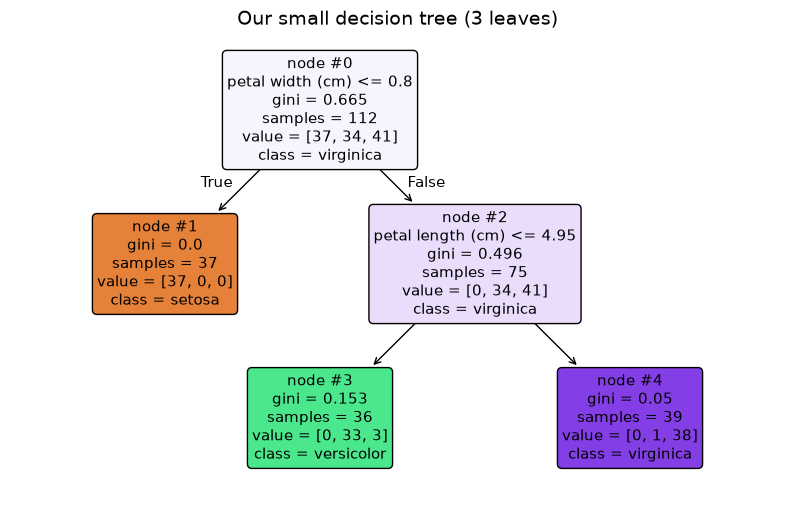

In [9]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(10, 6))
plot_tree(estimator, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, node_ids=True, fontsize=11, ax=ax)
ax.set_title('Our small decision tree (3 leaves)', fontsize=14)
plt.show()

The tree only ever asks about **petal width** and **petal length**, which matches what we saw in the scatter plots. Its first question, about petal width, separates all the *setosa* flowers in one step (that left box has gini = 0, perfectly pure). The second question, about petal length, then tries to split *versicolor* from *virginica*.

### What the tree's questions look like on a picture

Every question of the form *"Is feature ≤ number?"* draws a straight cut-off line. Since this tree only uses the two petal measurements, we can draw exactly what it does on a petal-length vs. petal-width plot. The colored areas show what the tree predicts for any flower that lands there; the dots are the training flowers.

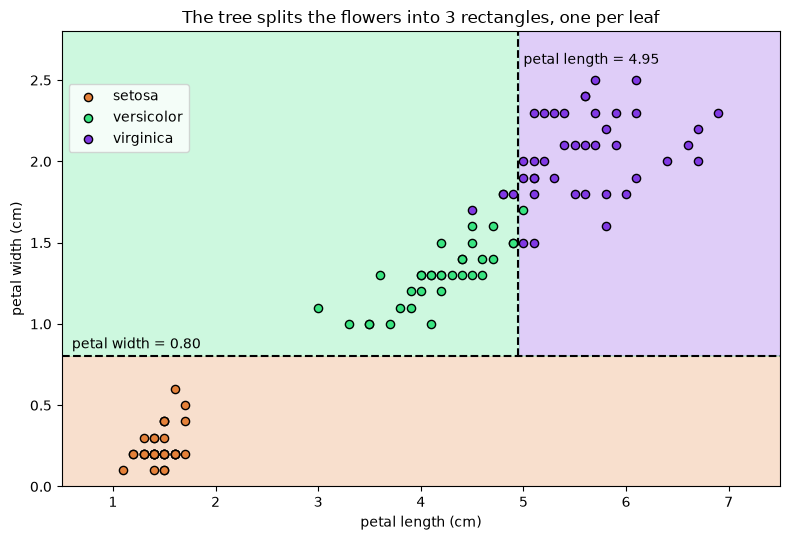

In [10]:
from matplotlib.colors import ListedColormap
species_cmap = ListedColormap(SPECIES_COLORS)

PL, PW = 2, 3   # column numbers of petal length and petal width in X
pl_grid, pw_grid = np.meshgrid(np.linspace(0.5, 7.5, 300), np.linspace(0, 2.8, 300))

# build a fake flower for every point on the grid; the sepal values do not matter
# to this tree (it never asks about them), so we just fill in typical values
grid = np.tile(np.median(X_train, axis=0), (pl_grid.size, 1))
grid[:, PL] = pl_grid.ravel()
grid[:, PW] = pw_grid.ravel()
region = estimator.predict(grid).reshape(pl_grid.shape)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.contourf(pl_grid, pw_grid, region, levels=[-0.5, 0.5, 1.5, 2.5], cmap=species_cmap, alpha=0.25)
for k, species in enumerate(iris.target_names):
    ax.scatter(X_train[y_train == k, PL], X_train[y_train == k, PW], color=SPECIES_COLORS[k],
               edgecolor='k', s=35, label=species)

# draw the two cut-off lines the tree learned
t = estimator.tree_
for node in range(t.node_count):
    if t.feature[node] == PW:
        ax.axhline(t.threshold[node], color='black', linestyle='--')
        ax.text(0.6, t.threshold[node] + 0.05, f'petal width = {t.threshold[node]:.2f}')
    elif t.feature[node] == PL:
        ax.plot([t.threshold[node]] * 2, [estimator.tree_.threshold[0], 2.8], color='black', linestyle='--')
        ax.text(t.threshold[node] + 0.05, 2.6, f'petal length = {t.threshold[node]:.2f}')
ax.set_xlabel('petal length (cm)')
ax.set_ylabel('petal width (cm)')
ax.set_title('The tree splits the flowers into 3 rectangles, one per leaf')
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.9))
plt.tight_layout()
plt.show()

The bottom strip is the "setosa" leaf, the left rectangle above it is the "versicolor" leaf, and the right rectangle is the "virginica" leaf. Notice a few green and purple dots on the wrong side of the vertical line; those are training flowers that this small tree gets wrong.

### How well does the tree do on the test flowers?

Accuracy on the 38 test flowers: 0.895
Number of mistakes: 4


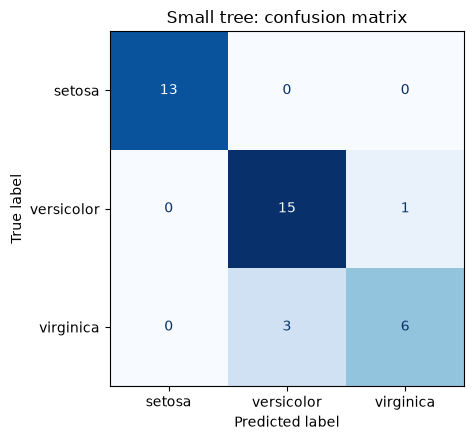

In [11]:
from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = estimator.predict(X_test)
small_tree_acc = metrics.accuracy_score(y_test, y_pred)
print(f"Accuracy on the {len(y_test)} test flowers: {small_tree_acc:.3f}")
print(f"Number of mistakes: {(y_pred != y_test).sum()}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=iris.target_names,
                                        cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Small tree: confusion matrix')
plt.tight_layout()
plt.show()

A **confusion matrix** counts every combination of *actual* species (rows) and *predicted* species (columns). The diagonal boxes are correct predictions; everything off the diagonal is a mistake. As expected, the tree never confuses *setosa* with anything; all its mistakes are between *versicolor* and *virginica*.


## Part 2: Opening the Tree: How It Is Stored

When we draw the tree, it looks like a picture of boxes and arrows. But inside the computer, scikit-learn stores the tree as a few **lists of numbers**, kept in the attribute `estimator.tree_`.

The idea is simple: every box (node) has an ID number, starting with **0 for the root**. Then there is one list for each piece of information, and position `i` in each list describes node `i`:

| List | What position `i` tells you |
|---|---|
| `children_left[i]` | the node number to go to if the answer to node `i`'s question is **yes** |
| `children_right[i]` | the node number to go to if the answer is **no** |
| `feature[i]` | **which** measurement node `i` asks about (0 = sepal length, 1 = sepal width, 2 = petal length, 3 = petal width) |
| `threshold[i]` | the **cut-off number** in node `i`'s question |

Leaves don't ask a question, so they have no children. scikit-learn marks this with **-1** in the children lists (and puts a meaningless placeholder value, -2, in `feature` and `threshold`).

Think of it like a "choose your own adventure" book: *"If yes, turn to page 1. If no, turn to page 2."* The lists are the instructions on each page.

The comments in the next cell come from the original scikit-learn example and describe the same thing in more technical language.

In [12]:
# The decision estimator has an attribute called tree_  which stores the entire
# tree structure and allows access to low level attributes. The binary tree
# tree_ is represented as a number of parallel arrays. The i-th element of each
# array holds information about the node `i`. Node 0 is the tree's root. NOTE:
# Some of the arrays only apply to either leaves or split nodes, resp. In this
# case the values of nodes of the other type are arbitrary!
#
# Among those arrays, we have:
#   - left_child, id of the left child of the node
#   - right_child, id of the right child of the node
#   - feature, feature used for splitting the node
#   - threshold, threshold value at the node
#

# Using those arrays, we can parse the tree structure:

n_nodes = estimator.tree_.node_count
children_left = estimator.tree_.children_left
children_right = estimator.tree_.children_right
feature = estimator.tree_.feature
threshold = estimator.tree_.threshold

Let's print the raw lists and compare them with the tree drawing above:

In [13]:
print("Number of nodes:", n_nodes)
print("children_left: ", children_left)
print("children_right:", children_right)
print("feature:       ", feature)
print("threshold:     ", threshold.round(2))

Number of nodes: 5
children_left:  [ 1 -1  3 -1 -1]
children_right: [ 2 -1  4 -1 -1]
feature:        [ 3 -2  2 -2 -2]
threshold:      [ 0.8  -2.    4.95 -2.   -2.  ]


**Try reading it yourself.** Position 0 (the root) says: `feature[0] = 3` (petal width) and `threshold[0] = 0.8`, so the question is *"Is petal width ≤ 0.8?"*. If yes, `children_left[0] = 1`, so go to node 1. If no, `children_right[0] = 2`, so go to node 2. Node 1 has `-1` for both children, so it is a leaf. Check that this matches the drawing!

The same information is easier to read as a table. The cell below builds one, with a row for each node. (`n_node_samples` and `value` are two more lists stored in `tree_`: how many training flowers reached each node, and the share of each species there.)

In [14]:
t = estimator.tree_
# t.value holds the share (or, in older scikit-learn versions, the count) of each species
# in every node; turning it into shares and multiplying by the number of flowers gives counts
shares = t.value[:, 0, :] / t.value[:, 0, :].sum(axis=1, keepdims=True)
counts = np.round(shares * t.n_node_samples[:, None]).astype(int)

node_table = pd.DataFrame({
    'node': range(n_nodes),
    'type': ['leaf' if children_left[i] == -1 else 'question' for i in range(n_nodes)],
    'question': ['' if children_left[i] == -1 else f'{iris.feature_names[feature[i]]} <= {threshold[i]:.2f}'
                 for i in range(n_nodes)],
    'if yes, go to': [children_left[i] if children_left[i] != -1 else '' for i in range(n_nodes)],
    'if no, go to': [children_right[i] if children_right[i] != -1 else '' for i in range(n_nodes)],
    'flowers here': t.n_node_samples,
    'setosa': counts[:, 0],
    'versicolor': counts[:, 1],
    'virginica': counts[:, 2],
}).set_index('node')
node_table

,type,question,"if yes, go to","if no, go to",flowers here,setosa,versicolor,virginica
node,,,,,,,,
0,question,petal width (cm) <= 0.80,1,2,112,37,34,41
1,leaf,,,,37,37,0,0
2,question,petal length (cm) <= 4.95,3,4,75,0,34,41
3,leaf,,,,36,0,33,3
4,leaf,,,,39,0,1,38


### Walking through the whole tree

The arrays tell us how each node connects to its children, but they don't directly say how **deep** each node is (how many questions it is below the root) or whether it is a leaf. We can work that out by **walking** through the tree.

The code below uses a **to-do list** (programmers call it a *stack*):

1. Start with the root on the to-do list, at depth 0.
2. Take a node off the list and record its depth.
3. If it is a question node (its left and right children are different), put **both children** on the to-do list, one level deeper.
4. If it is a leaf (both children are -1, so they are equal), mark it as a leaf.
5. Repeat until the to-do list is empty.

Then it prints the tree, indenting each node by its depth.

In [15]:
# The tree structure can be traversed to compute various properties such
# as the depth of each node and whether or not it is a leaf.
node_depth = np.zeros(shape=n_nodes, dtype=np.int64)
is_leaves = np.zeros(shape=n_nodes, dtype=bool)
stack = [(0, -1)]  # seed is the root node id and its parent depth
while len(stack) > 0:
    node_id, parent_depth = stack.pop()
    node_depth[node_id] = parent_depth + 1

    # If we have a test node
    if (children_left[node_id] != children_right[node_id]):
        stack.append((children_left[node_id], parent_depth + 1))
        stack.append((children_right[node_id], parent_depth + 1))
    else:
        is_leaves[node_id] = True

print("The binary tree structure has %s nodes and has "
      "the following tree structure:"
      % n_nodes)
for i in range(n_nodes):
    if is_leaves[i]:
        print("%snode=%s leaf node." % (node_depth[i] * "\t", i))
    else:
        print("%snode=%s test node: go to node %s if X[:, %s] <= %s else to "
              "node %s."
              % (node_depth[i] * "\t",
                 i,
                 children_left[i],
                 feature[i],
                 threshold[i],
                 children_right[i],
                 ))
print()

The binary tree structure has 5 nodes and has the following tree structure:
node=0 test node: go to node 1 if X[:, 3] <= 0.800000011920929 else to node 2.
	node=1 leaf node.
	node=2 test node: go to node 3 if X[:, 2] <= 4.950000047683716 else to node 4.
		node=3 leaf node.
		node=4 leaf node.



`X[:, 3]` means "column 3 of the data", which is petal width. Here is a friendlier version of the same printout that uses the feature names, the predicted species at each leaf, and rounded numbers:

In [16]:
for i in range(n_nodes):
    indent = "    " * node_depth[i]
    if is_leaves[i]:
        species = iris.target_names[np.argmax(t.value[i])]
        print(f"{indent}node {i}: LEAF -> predict {species}")
    else:
        print(f"{indent}node {i}: Is {iris.feature_names[feature[i]]} <= {threshold[i]:.2f}?  "
              f"yes -> node {children_left[i]},  no -> node {children_right[i]}")

node 0: Is petal width (cm) <= 0.80?  yes -> node 1,  no -> node 2
    node 1: LEAF -> predict setosa
    node 2: Is petal length (cm) <= 4.95?  yes -> node 3,  no -> node 4
        node 3: LEAF -> predict versicolor
        node 4: LEAF -> predict virginica



## Part 3: Following Individual Flowers Through the Tree

Now let's watch the tree make predictions, one flower at a time.

### Which nodes does each flower visit? (`decision_path`)

`decision_path` answers this question for every test flower. It returns a table with one row per flower and one column per node: a **1** means "this flower passed through this node" and a **0** means it did not. (To save memory, scikit-learn stores it in a compressed "sparse" format; `.toarray()` turns it back into an ordinary table.)

In [17]:
# First let's retrieve the decision path of each sample. The decision_path
# method allows to retrieve the node indicator functions. A non zero element of
# indicator matrix at the position (i, j) indicates that the sample i goes
# through the node j.

node_indicator = estimator.decision_path(X_test)

In [18]:
path_table = pd.DataFrame(node_indicator.toarray(),
                          columns=[f'node {j}' for j in range(n_nodes)])
path_table.index.name = 'test flower'
path_table.head(8)

,node 0,node 1,node 2,node 3,node 4
test flower,,,,,
0,1,0,1,0,1
1,1,0,1,1,0
2,1,1,0,0,0
3,1,0,1,0,1
4,1,1,0,0,0
5,1,0,1,0,1
6,1,1,0,0,0
7,1,0,1,1,0


Every row has a 1 in the `node 0` column, because every flower starts at the root. Each row then has 1s along exactly one route down the tree.

The same information as a picture, for the first 20 test flowers. Each row is a flower and each dark square is a node it visited:

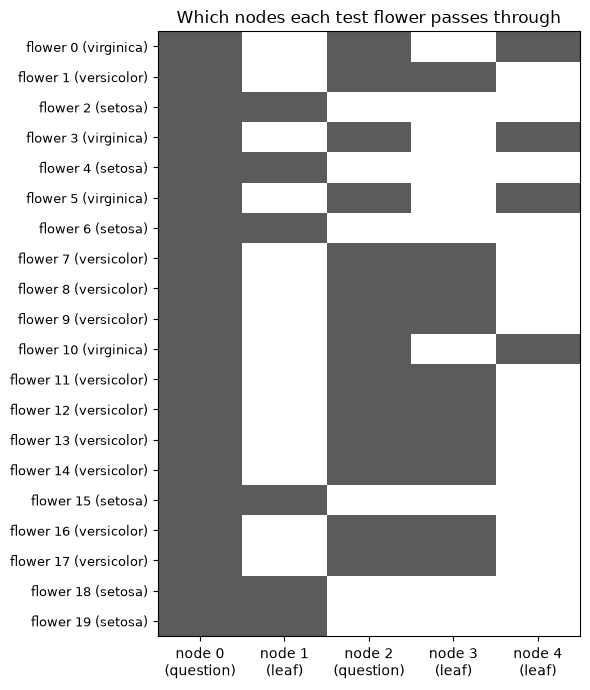

In [19]:
n_show = 20
fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(node_indicator.toarray()[:n_show], cmap='Greys', aspect='auto', vmin=0, vmax=1.4)
ax.set_xticks(range(n_nodes))
ax.set_xticklabels([f'node {j}\n({"leaf" if is_leaves[j] else "question"})' for j in range(n_nodes)])
ax.set_yticks(range(n_show))
ax.set_yticklabels([f'flower {i} ({iris.target_names[y_test[i]]})' for i in range(n_show)], fontsize=9)
ax.set_title('Which nodes each test flower passes through')
plt.tight_layout()
plt.show()

Notice the patterns: every flower visits node 0; *setosa* flowers stop right away at leaf node 1, while the others go on to node 2 and then end in leaf 3 or leaf 4.

### Where does each flower end up? (`apply`)

`apply` gives just the **final leaf** each flower lands in. The prediction is the species of that leaf.

In [20]:
# Similarly, we can also have the leaves ids reached by each sample.

leave_id = estimator.apply(X_test)

In [21]:
leaf_table = pd.DataFrame({
    'leaf reached': leave_id,
    'predicted species': iris.target_names[estimator.predict(X_test)],
    'actual species': iris.target_names[y_test],
})
leaf_table['correct?'] = leaf_table['predicted species'] == leaf_table['actual species']
leaf_table.index.name = 'test flower'
leaf_table.head(10)

,leaf reached,predicted species,actual species,correct?
test flower,,,,
0,4,virginica,virginica,True
1,3,versicolor,versicolor,True
2,1,setosa,setosa,True
3,4,virginica,virginica,True
4,1,setosa,setosa,True
5,4,virginica,virginica,True
6,1,setosa,setosa,True
7,3,versicolor,versicolor,True
8,3,versicolor,versicolor,True


### The questions answered by one flower

Now let's list the questions that test flower 0 answered on its way down.

The first two lines of the next cell pull out the list of nodes that flower 0 visits from the compressed `decision_path` table. (It is a shortcut for "find the columns where row 0 has a 1".) Then, for each question node on that path, it prints the flower's measurement and whether it was `<=` or `>` the cut-off.

In [22]:
# Now, it's possible to get the tests that were used to predict a sample or
# a group of samples. First, let's make it for the sample.

sample_id = 0
node_index = node_indicator.indices[node_indicator.indptr[sample_id]:
                                    node_indicator.indptr[sample_id + 1]]

print('Rules used to predict sample %s: ' % sample_id)
for node_id in node_index:
    if leave_id[sample_id] == node_id:
        continue

    if (X_test[sample_id, feature[node_id]] <= threshold[node_id]):
        threshold_sign = "<="
    else:
        threshold_sign = ">"

    print("decision id node %s : (X_test[%s, %s] (= %s) %s %s)"
          % (node_id,
             sample_id,
             feature[node_id],
             X_test[sample_id, feature[node_id]],
             threshold_sign,
             threshold[node_id]))

Rules used to predict sample 0: 
decision id node 0 : (X_test[0, 3] (= 2.4) > 0.800000011920929)
decision id node 2 : (X_test[0, 2] (= 5.1) > 4.950000047683716)


Read the output like this: *"At node 0, this flower's feature 3 (petal width) was 2.4, which is > 0.8, so it went right."* Here is the same thing in plain English, using a reusable function so we can try any flower:

In [23]:
def explain_prediction(tree_model, flower, flower_name='This flower'):
    # print, in plain English, every question a flower answers on its way to a leaf
    t = tree_model.tree_
    path = tree_model.decision_path(flower.reshape(1, -1)).indices
    print(f"{flower_name}: " + ", ".join(f"{name} = {value}" for name, value in zip(iris.feature_names, flower)))
    for node in path:
        if t.children_left[node] == -1:   # reached a leaf
            species = iris.target_names[np.argmax(t.value[node])]
            print(f"  node {node}: LEAF -> predict {species.upper()}")
        else:
            name, cut, value = iris.feature_names[t.feature[node]], t.threshold[node], flower[t.feature[node]]
            answer = 'yes' if value <= cut else 'no'
            next_node = t.children_left[node] if answer == 'yes' else t.children_right[node]
            print(f"  node {node}: Is {name} <= {cut:.2f}?  It is {value}, so {answer} -> go to node {next_node}")

explain_prediction(estimator, X_test[0], 'Test flower 0')
print("Actual species:", iris.target_names[y_test[0]])

Test flower 0: sepal length (cm) = 5.8, sepal width (cm) = 2.8, petal length (cm) = 5.1, petal width (cm) = 2.4
  node 0: Is petal width (cm) <= 0.80?  It is 2.4, so no -> go to node 2
  node 2: Is petal length (cm) <= 4.95?  It is 5.1, so no -> go to node 4
  node 4: LEAF -> predict VIRGINICA
Actual species: virginica


### Seeing the path

Let's highlight that path on the tree drawing. The function below draws a tree and gives a thick red outline to every node a particular flower passes through. We will reuse it later for the random forest.

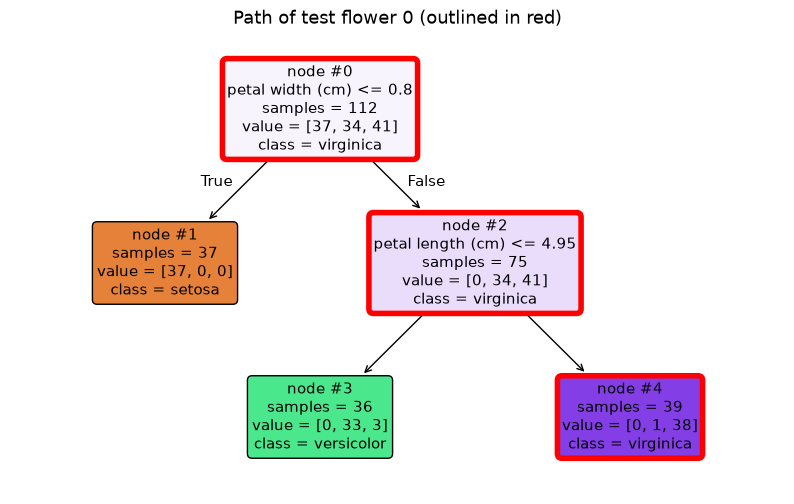

In [24]:
def draw_tree_with_path(tree_model, flower, ax, title='', path_color='red', fontsize=10):
    # draw a tree and outline the nodes that one flower passes through
    path = set(tree_model.decision_path(flower.reshape(1, -1)).indices)
    boxes = plot_tree(tree_model, feature_names=iris.feature_names, class_names=iris.target_names,
                      filled=True, rounded=True, node_ids=True, impurity=False,
                      fontsize=fontsize, ax=ax)
    for box in boxes:
        text = box.get_text()
        if text.startswith('node #'):
            node = int(text.split('#')[1].split('\n')[0])
            if node in path:
                box.get_bbox_patch().set_edgecolor(path_color)
                box.get_bbox_patch().set_linewidth(4)
    ax.set_title(title, fontsize=13)

fig, ax = plt.subplots(figsize=(10, 6))
draw_tree_with_path(estimator, X_test[0], ax, 'Path of test flower 0 (outlined in red)', fontsize=11)
plt.show()

### Which nodes do two flowers have in common?

Finally, the original example asks: for a *group* of flowers, which nodes did **all** of them pass through? It adds up the 1s in each column of the `decision_path` table; a node is shared if its total equals the number of flowers in the group.

In [25]:
# For a group of samples, we have the following common node.
sample_ids = [0, 1]
common_nodes = (node_indicator.toarray()[sample_ids].sum(axis=0) ==
                len(sample_ids))

common_node_id = np.arange(n_nodes)[common_nodes]

print("\nThe following samples %s share the node %s in the tree"
      % (sample_ids, common_node_id))
print("It is %s %% of all nodes." % (100 * len(common_node_id) / n_nodes,))


The following samples [0, 1] share the node [0 2] in the tree
It is 40.0 % of all nodes.


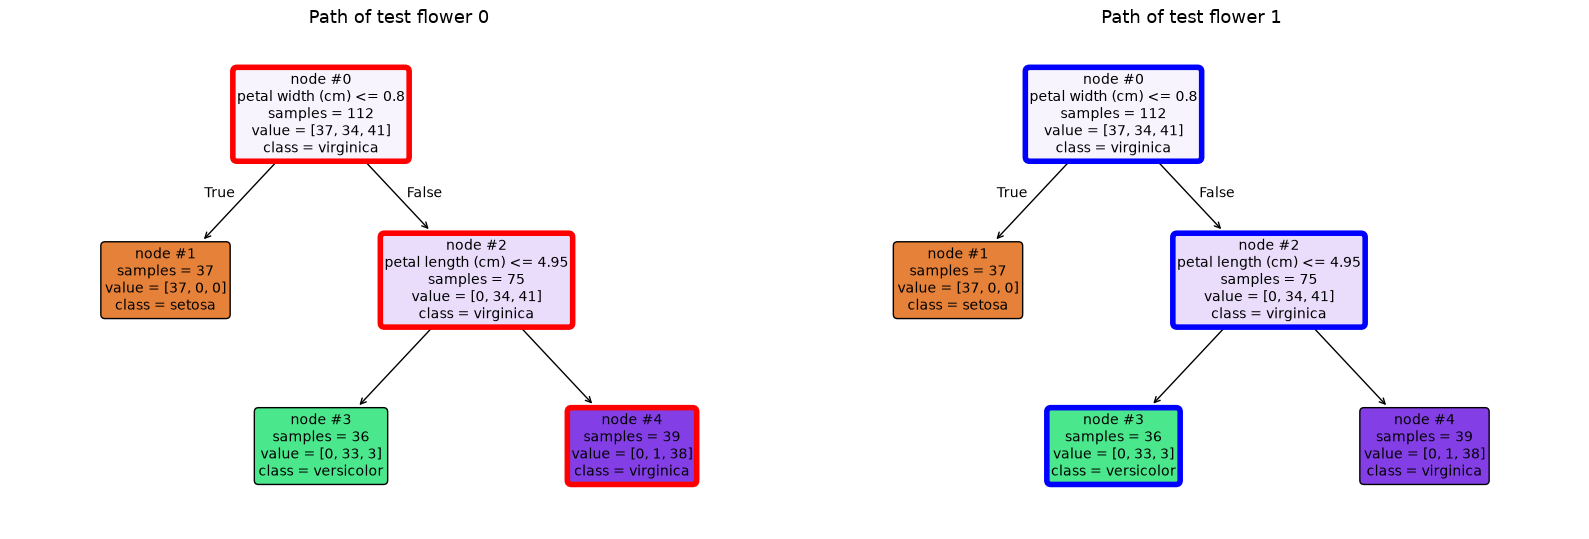

Test flower 1: sepal length (cm) = 6.0, sepal width (cm) = 2.2, petal length (cm) = 4.0, petal width (cm) = 1.0
  node 0: Is petal width (cm) <= 0.80?  It is 1.0, so no -> go to node 2
  node 2: Is petal length (cm) <= 4.95?  It is 4.0, so yes -> go to node 3
  node 3: LEAF -> predict VERSICOLOR


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
draw_tree_with_path(estimator, X_test[0], axes[0], 'Path of test flower 0', path_color='red')
draw_tree_with_path(estimator, X_test[1], axes[1], 'Path of test flower 1', path_color='blue')
plt.tight_layout()
plt.show()

explain_prediction(estimator, X_test[1], 'Test flower 1')

Both flowers go through node 0 and node 2, so they share those two nodes. Then they split up at node 2: flower 0 has a long petal and goes to the *virginica* leaf, while flower 1 has a shorter petal and goes to the *versicolor* leaf. Two flowers that share most of their path were treated as "similar" by the tree.


## Part 4: The Weaknesses of a Single Tree

Iris is an easy dataset, so a single tree already does well. But two weaknesses of decision trees still show up, and on harder real-world data (like the diabetes data in Example 1) they become serious.

### Weakness 1: Big trees memorize (overfitting)

What if we take away the 3-leaf limit and let the tree grow until every leaf is pure?

Number of leaves:   7
Number of nodes:    13
Depth:              4
Training accuracy:  1.000
Testing accuracy:   0.974


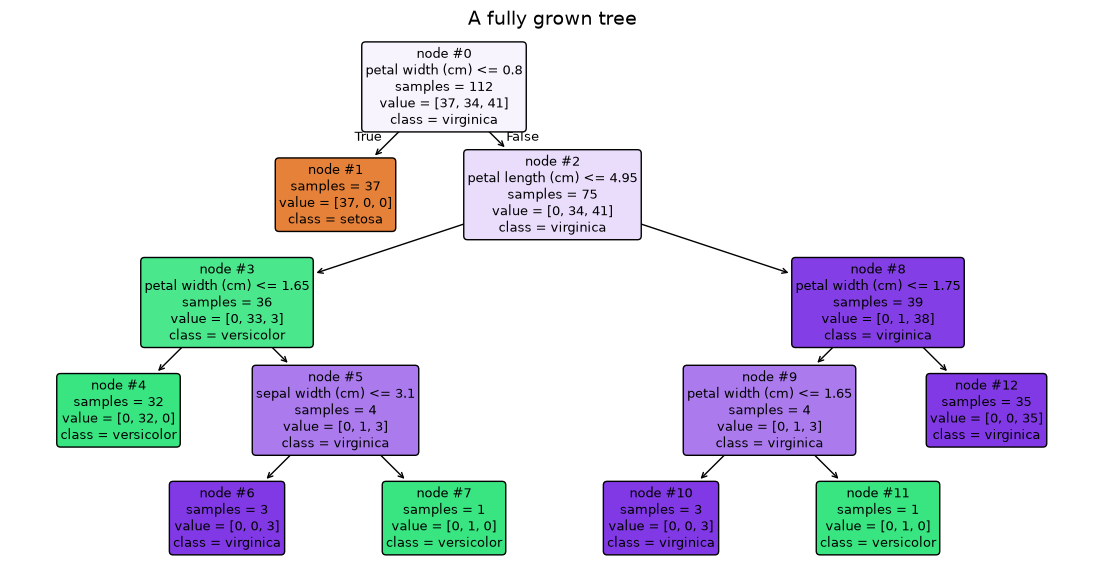

In [27]:
full_tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)

print("Number of leaves:  ", full_tree.get_n_leaves())
print("Number of nodes:   ", full_tree.tree_.node_count)
print("Depth:             ", full_tree.get_depth())
print(f"Training accuracy:  {full_tree.score(X_train, y_train):.3f}")
print(f"Testing accuracy:   {full_tree.score(X_test, y_test):.3f}")

fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(full_tree, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, node_ids=True, impurity=False, fontsize=9, ax=ax)
ax.set_title('A fully grown tree', fontsize=14)
plt.show()

The fully grown tree gets **100% of the training flowers right**: it keeps adding questions until every leaf contains just one species. Look at the leaves near the bottom: some contain only 1 or 2 flowers. Those questions were added just to handle a few unusual training flowers. That is **memorizing** rather than learning a general rule, and it is called **overfitting**. Here it happens to work out on the test set, but there is no guarantee that a rule built for 1 or 2 flowers will hold for new ones.

### Weakness 2: A little change in the data can change the tree (instability)

Let's build 5 fully grown trees, each on a **random 90%** of the training flowers, and compare them.

Tree 1: 7 leaves, depth 4, test accuracy 0.974
Tree 2: 5 leaves, depth 4, test accuracy 0.974
Tree 3: 5 leaves, depth 4, test accuracy 0.974
Tree 4: 7 leaves, depth 4, test accuracy 0.974
Tree 5: 7 leaves, depth 4, test accuracy 0.974


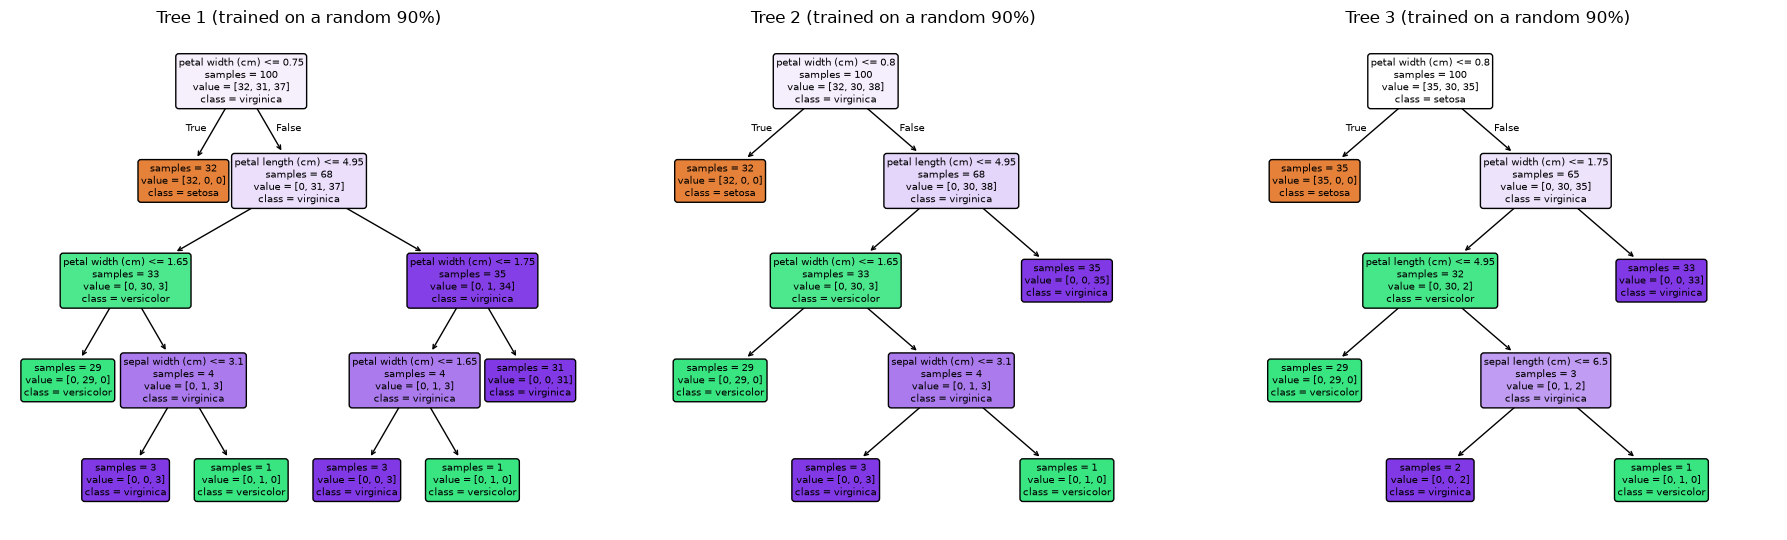

The 5 trees disagree about 0 of the 38 test flowers.


In [28]:
rng = np.random.default_rng(7)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
predictions = []
for i in range(5):
    keep = rng.choice(len(X_train), size=int(0.9 * len(X_train)), replace=False)
    t_i = DecisionTreeClassifier(random_state=0).fit(X_train[keep], y_train[keep])
    predictions.append(t_i.predict(X_test))
    print(f"Tree {i+1}: {t_i.get_n_leaves()} leaves, depth {t_i.get_depth()}, "
          f"test accuracy {t_i.score(X_test, y_test):.3f}")
    if i < 3:
        plot_tree(t_i, filled=True, rounded=True, impurity=False, feature_names=iris.feature_names,
                  class_names=iris.target_names, fontsize=7, ax=axes[i])
        axes[i].set_title(f'Tree {i+1} (trained on a random 90%)')
plt.tight_layout()
plt.show()

predictions = np.array(predictions)
disagree = (predictions.min(axis=0) != predictions.max(axis=0)).sum()
print(f"The 5 trees disagree about {disagree} of the {len(X_test)} test flowers.")

Removing just 10% of the training flowers gives trees with **different shapes**: different numbers of leaves, and different questions further down, where the trees try to separate *versicolor* from *virginica* (for example, compare the second question on the right-hand side of each drawing).

On this particular test set the 5 trees still happen to agree on every flower, because iris is an easy dataset and most test flowers are far from the borderline. But a flower near the *versicolor*/*virginica* border could get a different answer depending on which tree we happened to build. A model whose details change with small changes in the data is called **unstable** (or *high variance*). On harder data, such as the diabetes data in Example 1, this instability changes the predictions for many patients.

**The challenge:** can we keep the power of big trees but make the result more stable? **Yes, with a random forest.**


## Part 5: Building a Random Forest by Hand, Step by Step

### The big idea: the wisdom of crowds

If you ask one friend to guess the number of jelly beans in a jar, they will probably be pretty far off. If you ask 500 people and average their guesses, the answer is often surprisingly close, because their individual errors (some too high, some too low) cancel out.

A random forest does the same with trees: it builds **many** trees and lets them **vote**. With three species, each tree votes for one species, and **the species with the most votes wins**.

But the crowd only helps if its members make **different** mistakes. 100 identical trees would always agree, and voting would add nothing. So a random forest makes its trees different on purpose, using **two kinds of randomness**:

```
                         Training flowers (112)
                                   |
       +------------------+--------+---------+------------------+
       |                  |                  |                  |
STEP 1: Bootstrap  Bootstrap sample 2  Bootstrap sample 3 ...  sample N
   sample 1               |                  |                  |
       |                  |                  |                  |
STEP 2 & 3: grow a tree, using only a random few features at each question
    Tree 1             Tree 2             Tree 3      ...    Tree N
       |                  |                  |                  |
     vote               vote               vote               vote
       +------------------+--------+---------+------------------+
                                   |
            STEP 4: the species with the most votes wins
```

### Step 1: Bootstrap sampling (random rows)

Each tree gets its own dataset, made by **sampling with replacement**. Picture writing each training flower's number on a slip of paper and putting all 112 slips in a hat. Draw a slip, write down the number, **put the slip back**, and repeat 112 times.

Because slips go back in the hat, some flowers are picked several times and others are never picked at all. The result is called a **bootstrap sample**. Every tree gets a different one.

Below are 5 bootstrap samples, showing how many times each of the first 15 training flowers was picked:

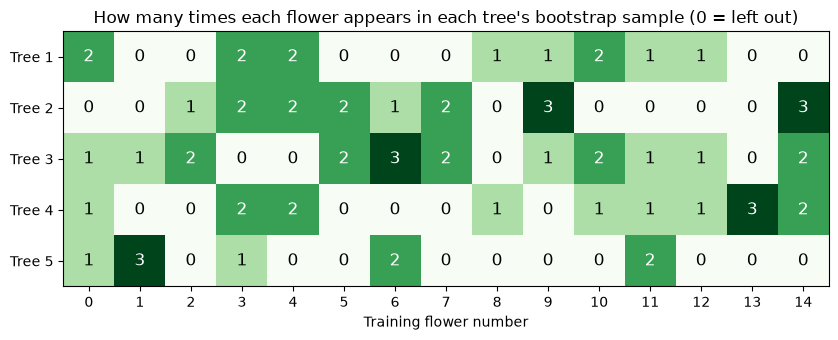

Bootstrap sample 1: 73 of 112 different flowers picked (65%), 39 left out
Bootstrap sample 2: 61 of 112 different flowers picked (54%), 51 left out
Bootstrap sample 3: 69 of 112 different flowers picked (62%), 43 left out
Bootstrap sample 4: 73 of 112 different flowers picked (65%), 39 left out
Bootstrap sample 5: 65 of 112 different flowers picked (58%), 47 left out


In [29]:
rng = np.random.default_rng(3)
n = len(X_train)
n_samples, n_flowers_shown = 5, 15

pick_counts = np.zeros((n_samples, n), dtype=int)
for s in range(n_samples):
    boot = rng.choice(n, size=n, replace=True)   # replace=True means "put the slip back"
    np.add.at(pick_counts[s], boot, 1)

shown = pick_counts[:, :n_flowers_shown]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.imshow(shown, cmap='Greens', vmin=0, vmax=max(3, shown.max()))
for s in range(n_samples):
    for f in range(n_flowers_shown):
        ax.text(f, s, shown[s, f], ha='center', va='center',
                color='white' if shown[s, f] >= 2 else 'black', fontsize=12)
ax.set_xticks(range(n_flowers_shown))
ax.set_xlabel('Training flower number')
ax.set_yticks(range(n_samples))
ax.set_yticklabels([f'Tree {s+1}' for s in range(n_samples)])
ax.set_title("How many times each flower appears in each tree's bootstrap sample (0 = left out)")
plt.tight_layout()
plt.show()

for s in range(n_samples):
    picked = (pick_counts[s] > 0).sum()
    print(f"Bootstrap sample {s+1}: {picked} of {n} different flowers picked ({picked/n:.0%}), "
          f"{n - picked} left out")

Each tree sees a different version of the data. On average, about **63%** of the flowers end up in each bootstrap sample and about **37%** are left out. (The left-out flowers are called **out-of-bag** flowers; we will use them in Part 6.)

### Step 2: Random features at each question

In Part 1 we saw that **petal width** and **petal length** are by far the most useful measurements. If every tree could always choose from all four measurements, they would all start with nearly the same petal question and end up looking alike.

So in a random forest, **every time a tree asks a question, it may only choose from a small random handful of the features**. The usual choice is the square root of the number of features: $\sqrt{4} = 2$. A fresh random handful is drawn for every question in every tree. Sometimes neither petal measurement is in the handful, and the tree has to make do with a sepal measurement.

In [30]:
rng = np.random.default_rng(1)
n_features_per_question = int(np.sqrt(X.shape[1]))   # sqrt(4) = 2
print("Features allowed per question:", n_features_per_question, "\n")
for question in range(1, 7):
    allowed = rng.choice(iris.feature_names, size=n_features_per_question, replace=False)
    print(f"Question {question}: may only choose between {' and '.join(allowed)}")

Features allowed per question: 2 

Question 1: may only choose between sepal width (cm) and petal length (cm)
Question 2: may only choose between sepal length (cm) and petal length (cm)
Question 3: may only choose between petal width (cm) and petal length (cm)
Question 4: may only choose between petal width (cm) and sepal length (cm)
Question 5: may only choose between petal width (cm) and sepal length (cm)
Question 6: may only choose between sepal width (cm) and petal length (cm)


In scikit-learn, the option `max_features='sqrt'` does this for us.

### Step 3: Grow many trees

Now we combine Steps 1 and 2 to grow **25 trees**. Each tree gets its own bootstrap sample and uses `max_features='sqrt'`. We let every tree grow fully; each one overfits in its own way, and the vote in Step 4 will smooth that out.

In [31]:
n_trees = 25
my_trees = []
rng = np.random.default_rng(0)

for i in range(n_trees):
    # Step 1: bootstrap sample of the training flowers
    boot_idx = rng.choice(n, size=n, replace=True)

    # Steps 2 + 3: grow a full tree that sees only 2 random features at each question
    tree = DecisionTreeClassifier(max_features='sqrt', random_state=i)
    tree.fit(X_train[boot_idx], y_train[boot_idx])
    my_trees.append(tree)

summary = pd.DataFrame({
    'root question': [f'{iris.feature_names[t.tree_.feature[0]]} <= {t.tree_.threshold[0]:.2f}' for t in my_trees],
    'nodes': [t.tree_.node_count for t in my_trees],
    'depth': [t.get_depth() for t in my_trees],
    'test accuracy': [round(t.score(X_test, y_test), 3) for t in my_trees],
}, index=[f'Tree {i+1}' for i in range(n_trees)])
summary.head(10)

,root question,nodes,depth,test accuracy
Tree 1,petal width (cm) <= 0.80,11,4,0.921
Tree 2,petal width (cm) <= 0.80,13,4,0.947
Tree 3,petal width (cm) <= 0.75,13,6,0.947
Tree 4,sepal length (cm) <= 5.45,19,6,0.895
Tree 5,petal length (cm) <= 4.95,17,5,0.895
Tree 6,petal width (cm) <= 0.70,7,3,0.974
Tree 7,petal length (cm) <= 4.95,21,6,0.921
Tree 8,petal length (cm) <= 4.95,19,6,0.868
Tree 9,petal width (cm) <= 0.80,15,4,0.974
Tree 10,petal length (cm) <= 2.65,11,4,0.974


The trees differ in their first question, their size, and their accuracy. Let's count which measurement each of the 25 trees used for its root question:

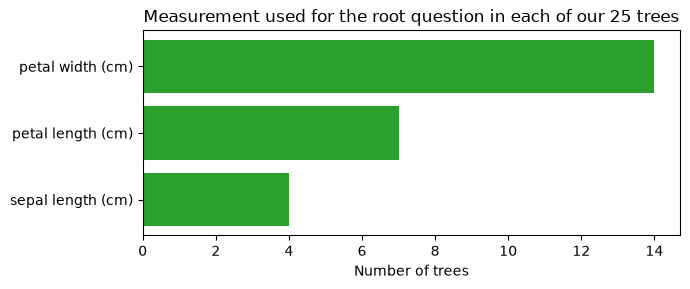

In [32]:
root_counts = summary['root question'].str.split(' <=').str[0].value_counts()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(root_counts.index[::-1], root_counts.values[::-1], color='tab:green')
ax.set_xlabel('Number of trees')
ax.set_title(f'Measurement used for the root question in each of our {n_trees} trees')
plt.tight_layout()
plt.show()

### Step 4: Let the trees vote

To classify a test flower, every tree makes a prediction and the forest picks the species with the **most votes**. Let's see the vote counts for the first 8 test flowers:

In [33]:
# one row per tree, one column per test flower; each entry is 0, 1 or 2
all_votes = np.array([t.predict(X_test) for t in my_trees])

# count the votes for each species, for each test flower
vote_counts = np.array([(all_votes == k).sum(axis=0) for k in range(3)]).T
my_forest_pred = vote_counts.argmax(axis=1)   # the species with the most votes

vote_table = pd.DataFrame(vote_counts, columns=[f'votes: {s}' for s in iris.target_names])
vote_table['forest prediction'] = iris.target_names[my_forest_pred]
vote_table['actual'] = iris.target_names[y_test]
vote_table.index.name = 'test flower'
vote_table.head(8)

,votes: setosa,votes: versicolor,votes: virginica,forest prediction,actual
test flower,,,,,
0,0,0,25,virginica,virginica
1,0,23,2,versicolor,versicolor
2,25,0,0,setosa,setosa
3,0,1,24,virginica,virginica
4,25,0,0,setosa,setosa
5,0,1,24,virginica,virginica
6,25,0,0,setosa,setosa
7,0,25,0,versicolor,versicolor


Here are the votes for **all** test flowers. Each bar is one flower, split into colors showing how many of the 25 trees voted for each species. The colored squares below the bars show each flower's actual species, and an **X** marks a flower the forest got wrong.

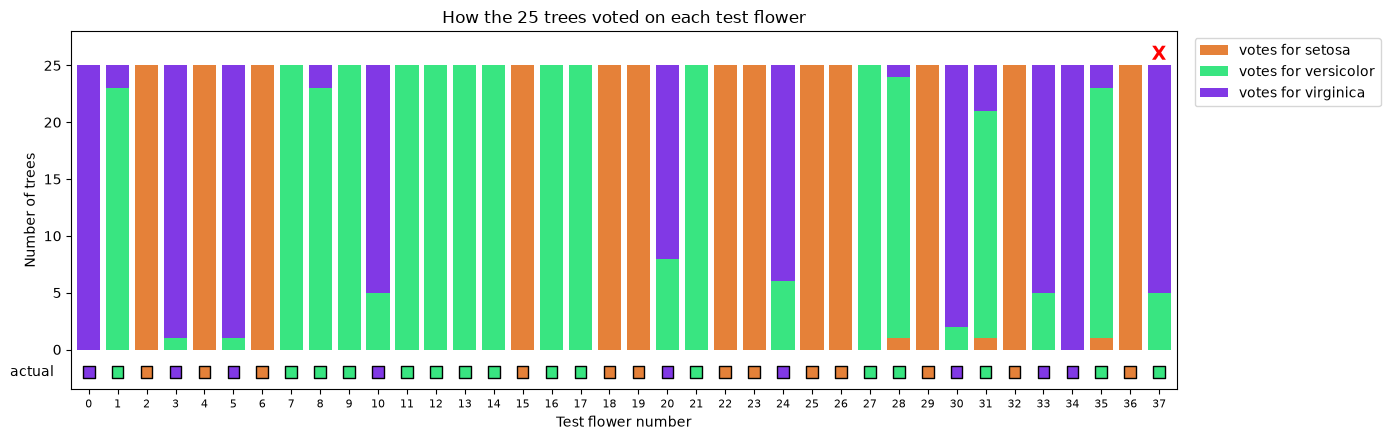

In [34]:
fig, ax = plt.subplots(figsize=(14, 4.5))
flowers = np.arange(len(X_test))
bottom = np.zeros(len(X_test))
for k, species in enumerate(iris.target_names):
    ax.bar(flowers, vote_counts[:, k], bottom=bottom, color=SPECIES_COLORS[k], label=f'votes for {species}')
    bottom += vote_counts[:, k]
ax.scatter(flowers, np.full(len(X_test), -2), c=[SPECIES_COLORS[k] for k in y_test],
           marker='s', s=70, edgecolor='k', clip_on=False)
for f in flowers[my_forest_pred != y_test]:
    ax.text(f, n_trees + 0.5, 'X', ha='center', fontsize=14, fontweight='bold', color='red')
ax.text(-1.2, -2, 'actual', ha='right', va='center')
ax.set_ylim(-3.5, n_trees + 3)
ax.set_xlim(-0.6, len(X_test) - 0.4)
ax.set_xticks(flowers)
ax.set_xticklabels(flowers, fontsize=8)
ax.set_xlabel('Test flower number')
ax.set_ylabel('Number of trees')
ax.set_title('How the 25 trees voted on each test flower')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

For most flowers the vote is **unanimous** (one solid color), especially for *setosa*. The bars with two colors are the borderline flowers, mostly between *versicolor* and *virginica*, where the trees disagree. This is useful information on its own: the size of the winning share tells us **how confident** the forest is.

### Does the crowd beat the individuals?

Each gray dot below is the test accuracy of one of our trees on its own. The green line is the forest's accuracy.

Average single tree:          0.935
Worst single tree:            0.842
Best single tree:             0.974
Hand-built forest (25 trees): 0.974


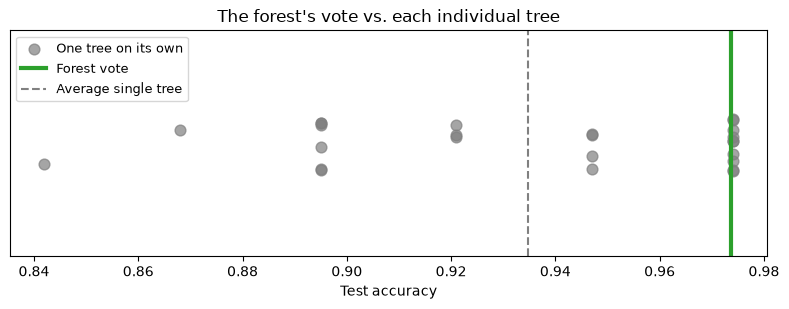

In [35]:
single_accs = summary['test accuracy'].values
my_forest_acc = metrics.accuracy_score(y_test, my_forest_pred)
print(f"Average single tree:          {single_accs.mean():.3f}")
print(f"Worst single tree:            {single_accs.min():.3f}")
print(f"Best single tree:             {single_accs.max():.3f}")
print(f"Hand-built forest (25 trees): {my_forest_acc:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, n_trees)
ax.scatter(single_accs, jitter, s=60, alpha=0.7, color='tab:gray', label='One tree on its own')
ax.axvline(my_forest_acc, color='tab:green', linewidth=3, label='Forest vote')
ax.axvline(single_accs.mean(), color='gray', linestyle='--', label='Average single tree')
ax.set_yticks([])
ax.set_ylim(-0.6, 0.6)
ax.set_xlabel('Test accuracy')
ax.set_title("The forest's vote vs. each individual tree")
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

The forest does better than the average tree, and it doesn't depend on luck: we don't need to know in advance which tree is the best one, because the vote takes care of it.

### Recap: the random forest recipe

1. **Bootstrap:** give each tree its own random sample of the rows, drawn with replacement.
2. **Random features:** at every question, let the tree choose from only a few random features.
3. **Grow:** grow each tree fully.
4. **Vote:** predict the class with the most votes.

Steps 1 and 2 make the trees **different**; Step 4 makes their individual mistakes **cancel out**.


## Part 6: Random Forest with scikit-learn, and a Look Inside

`RandomForestClassifier` does all four steps for us:

| Setting | Meaning | Matching step |
|---|---|---|
| `n_estimators=100` | how many trees to grow | Step 3 |
| `bootstrap=True` (the default) | give each tree a bootstrap sample | Step 1 |
| `max_features='sqrt'` (the default) | number of random features per question | Step 2 |
| `random_state=0` | makes the randomness repeatable | |

In [36]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=0)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
print(f"Random forest accuracy: {metrics.accuracy_score(y_test, rf_pred):.3f}")

Random forest accuracy: 0.974


### A forest is just a list of trees

The trees inside the forest are stored in `rf.estimators_`. Each one is an ordinary `DecisionTreeClassifier`, with the same `tree_` arrays we explored in Part 2. Everything we learned about opening up a single tree works on every tree in the forest.

In [37]:
print("Number of trees in the forest:", len(rf.estimators_))
print("Type of the first tree:       ", type(rf.estimators_[0]).__name__)
print()
for i, tree_i in enumerate(rf.estimators_[:5]):
    t_i = tree_i.tree_
    print(f"Tree {i}: {t_i.node_count} nodes, depth {tree_i.get_depth()}, "
          f"root question: Is {iris.feature_names[t_i.feature[0]]} <= {t_i.threshold[0]:.2f}?")

Number of trees in the forest: 100
Type of the first tree:        DecisionTreeClassifier

Tree 0: 13 nodes, depth 4, root question: Is petal width (cm) <= 0.75?
Tree 1: 15 nodes, depth 5, root question: Is petal width (cm) <= 0.75?
Tree 2: 11 nodes, depth 4, root question: Is sepal length (cm) <= 5.45?
Tree 3: 25 nodes, depth 5, root question: Is sepal length (cm) <= 5.75?
Tree 4: 9 nodes, depth 3, root question: Is petal width (cm) <= 0.75?


### Following one flower through several trees of the forest

In Part 3 we followed test flower 0 through our single tree. Now let's follow the **same flower** through the first three trees of the forest, using the same `draw_tree_with_path` function. Each tree asks different questions, takes the flower down a different route, and casts its own vote.

One detail to notice in these drawings: `samples` counts how many **different** flowers reached a box, while `value` counts flowers **including repeats**. That is why the root says something like `samples = 69` but its `value` numbers add up to 112. The difference is the bootstrap from Step 1: some flowers were picked more than once, and some not at all.

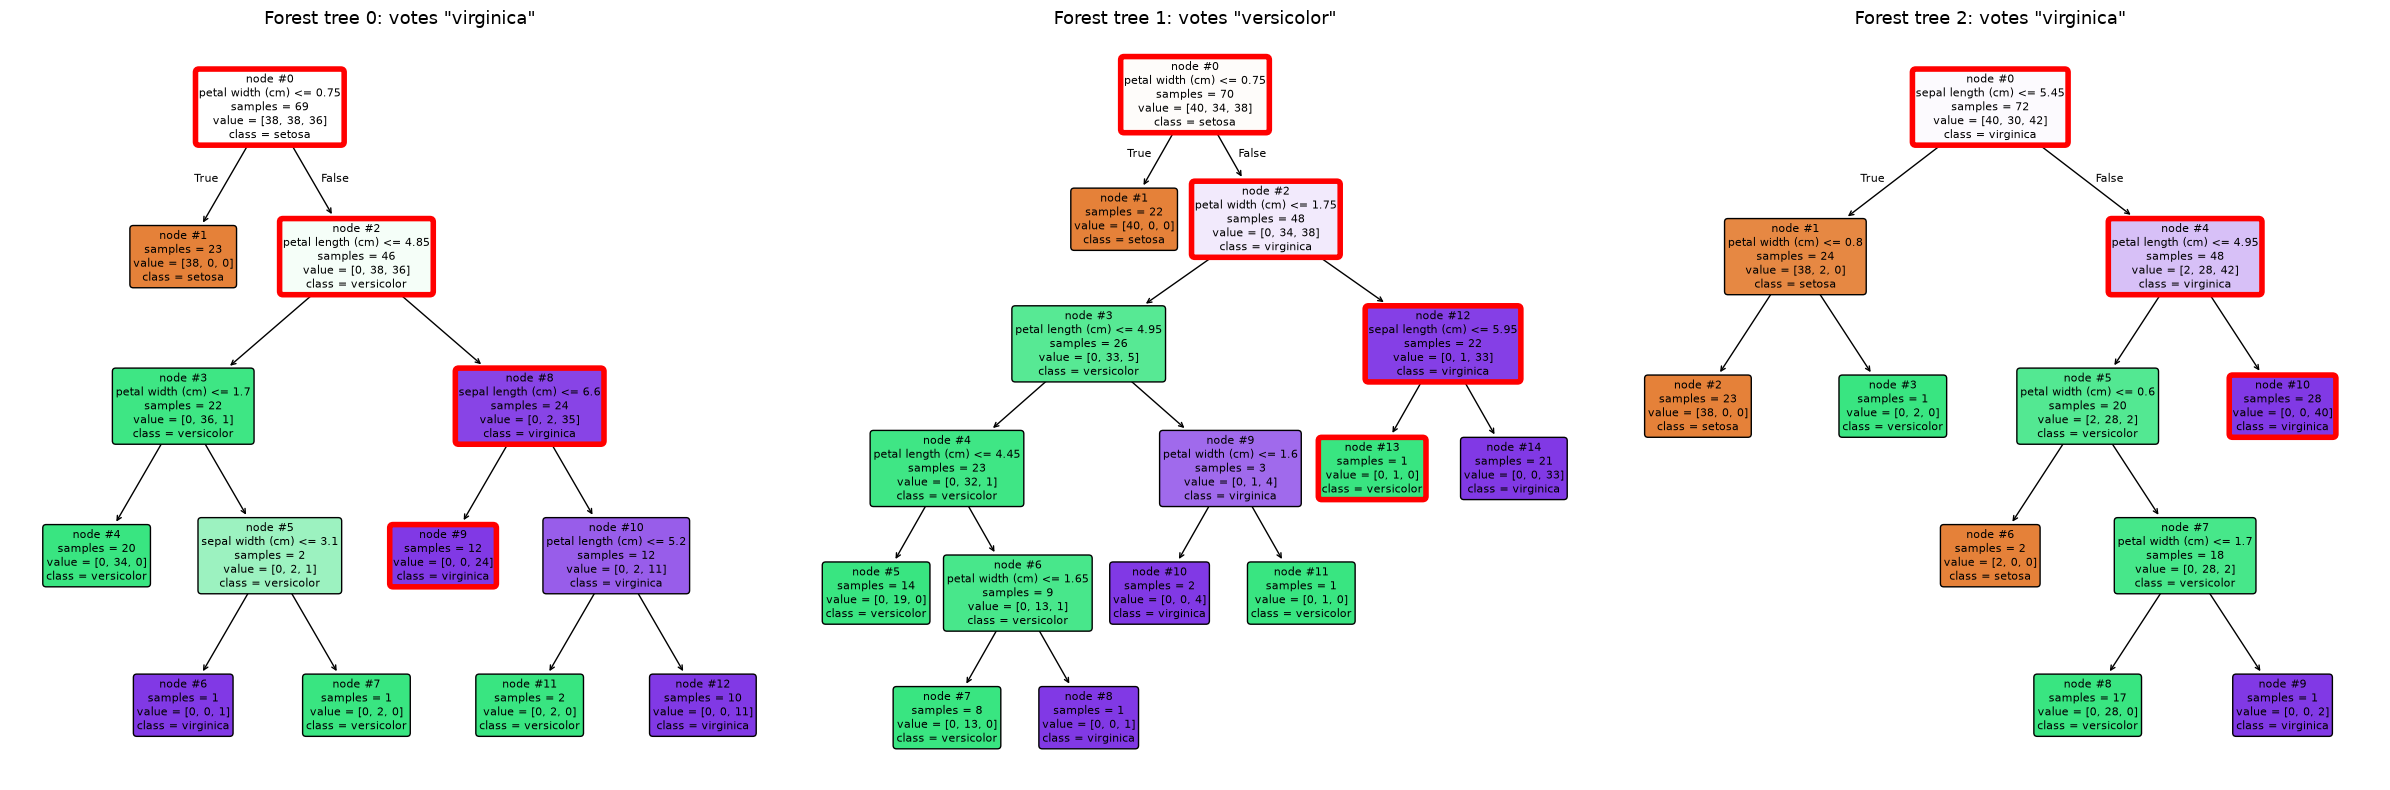

--- Forest tree 0 ---
Test flower 0: sepal length (cm) = 5.8, sepal width (cm) = 2.8, petal length (cm) = 5.1, petal width (cm) = 2.4
  node 0: Is petal width (cm) <= 0.75?  It is 2.4, so no -> go to node 2
  node 2: Is petal length (cm) <= 4.85?  It is 5.1, so no -> go to node 8
  node 8: Is sepal length (cm) <= 6.60?  It is 5.8, so yes -> go to node 9
  node 9: LEAF -> predict VIRGINICA
--- Forest tree 1 ---
Test flower 0: sepal length (cm) = 5.8, sepal width (cm) = 2.8, petal length (cm) = 5.1, petal width (cm) = 2.4
  node 0: Is petal width (cm) <= 0.75?  It is 2.4, so no -> go to node 2
  node 2: Is petal width (cm) <= 1.75?  It is 2.4, so no -> go to node 12
  node 12: Is sepal length (cm) <= 5.95?  It is 5.8, so yes -> go to node 13
  node 13: LEAF -> predict VERSICOLOR
--- Forest tree 2 ---
Test flower 0: sepal length (cm) = 5.8, sepal width (cm) = 2.8, petal length (cm) = 5.1, petal width (cm) = 2.4
  node 0: Is sepal length (cm) <= 5.45?  It is 5.8, so no -> go to node 4
  no

In [38]:
flower_id = 0
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
for i, ax in enumerate(axes):
    tree_i = rf.estimators_[i]
    vote = iris.target_names[int(tree_i.predict(X_test[[flower_id]])[0])]
    draw_tree_with_path(tree_i, X_test[flower_id], ax,
                        f'Forest tree {i}: votes "{vote}"', fontsize=8)
plt.tight_layout()
plt.show()

for i in range(3):
    print(f"--- Forest tree {i} ---")
    explain_prediction(rf.estimators_[i], X_test[flower_id], f'Test flower {flower_id}')

### Counting all 100 votes for one flower

The forest's **probability** for each species (`predict_proba`) is essentially the share of trees that voted for it. (Technically, scikit-learn averages the probability from each tree, a "soft vote". Fully grown trees almost always give 100% to one species, so this is practically the same as counting votes.)

Let's find the test flower the forest is **least sure** about and compare the forest's answer with our small tree's answer.

Least certain test flower: number 20 (actual species: virginica)
  setosa      trees voting:   0   forest probability: 0.00   small-tree probability: 0.00
  versicolor  trees voting:  27   forest probability: 0.27   small-tree probability: 0.92
  virginica   trees voting:  73   forest probability: 0.73   small-tree probability: 0.08


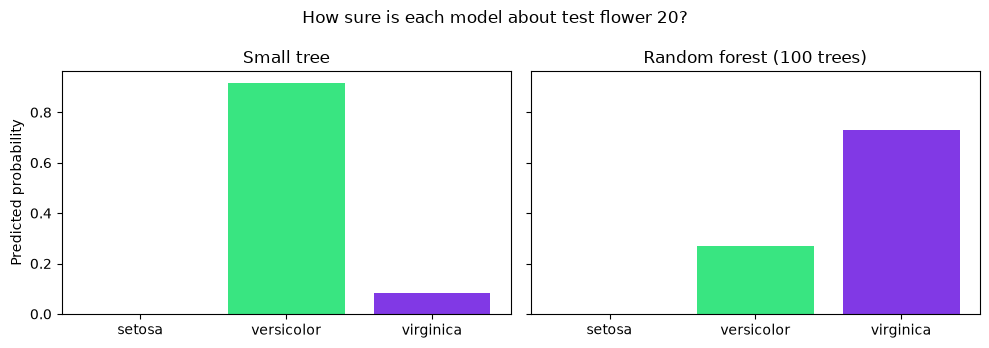

In [39]:
rf_prob = rf.predict_proba(X_test)
unsure = int(np.argmin(rf_prob.max(axis=1)))   # flower whose top probability is lowest

forest_votes = np.array([int(t.predict(X_test[[unsure]])[0]) for t in rf.estimators_])
print(f"Least certain test flower: number {unsure} (actual species: {iris.target_names[y_test[unsure]]})")
for k, species in enumerate(iris.target_names):
    print(f"  {species:<11} trees voting: {(forest_votes == k).sum():3d}   "
          f"forest probability: {rf_prob[unsure, k]:.2f}   "
          f"small-tree probability: {estimator.predict_proba(X_test[[unsure]])[0, k]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
axes[0].bar(iris.target_names, estimator.predict_proba(X_test[[unsure]])[0], color=SPECIES_COLORS)
axes[0].set_title('Small tree')
axes[1].bar(iris.target_names, rf_prob[unsure], color=SPECIES_COLORS)
axes[1].set_title('Random forest (100 trees)')
axes[0].set_ylabel('Predicted probability')
fig.suptitle(f'How sure is each model about test flower {unsure}?')
plt.tight_layout()
plt.show()

Look closely at this flower. The small tree is very confident that it is *versicolor*, and it is **wrong**. The forest leans toward the correct answer, *virginica*, but a quarter of its trees disagree, so it also signals doubt.

The small tree's probability comes from the mix of training flowers in **one leaf**, so every flower in that leaf gets exactly the same answer, whether it is a typical flower or a borderline one. The forest combines 100 different trees, so it can give each flower its own level of confidence. A split vote like this one is the forest's way of saying *"this flower is hard to classify."*

### How many trees do we need?

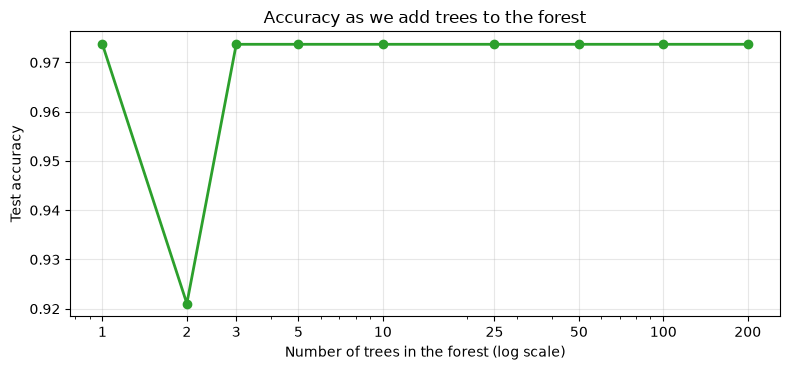

In [40]:
tree_counts = [1, 2, 3, 5, 10, 25, 50, 100, 200]
accs = [RandomForestClassifier(n_estimators=k, random_state=0).fit(X_train, y_train).score(X_test, y_test)
        for k in tree_counts]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(tree_counts, accs, 'o-', color='tab:green', linewidth=2)
ax.set_xscale('log')
ax.set_xticks(tree_counts)
ax.set_xticklabels(tree_counts)
ax.set_xlabel('Number of trees in the forest (log scale)')
ax.set_ylabel('Test accuracy')
ax.set_title('Accuracy as we add trees to the forest')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

On iris the line is almost flat. Iris is easy, and with only 38 test flowers, **one flower** changing from right to wrong moves the accuracy by about 2.6%, so there is little room to see improvement. (The dip at 2 trees happens because two trees that disagree produce a tie, and ties are broken arbitrarily; very small forests can be erratic.)

What more trees buy you is a **steadier vote**: as the forest grows, the vote shares for each flower settle down and stop depending on which few trees you happened to build. More trees rarely hurt accuracy; they mostly cost computer time.

### Out-of-bag score: a free check using the left-out flowers

Each tree never saw about 37% of the training flowers (its out-of-bag flowers). We can test every training flower using only the trees that never saw it. This gives an honest accuracy estimate without using the test set at all.

In [41]:
rf_oob = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=0).fit(X_train, y_train)
print(f"Out-of-bag accuracy estimate (training flowers only): {rf_oob.oob_score_:.3f}")
print(f"Accuracy on the real test set:                        {rf_oob.score(X_test, y_test):.3f}")

Out-of-bag accuracy estimate (training flowers only): 0.955
Accuracy on the real test set:                        0.974


### Which measurements matter most? (feature importance)

Each question in each tree lowers the Gini impurity. A feature's **importance** adds up how much it lowered impurity over all questions in all 100 trees, scaled so all four importances add up to 1.

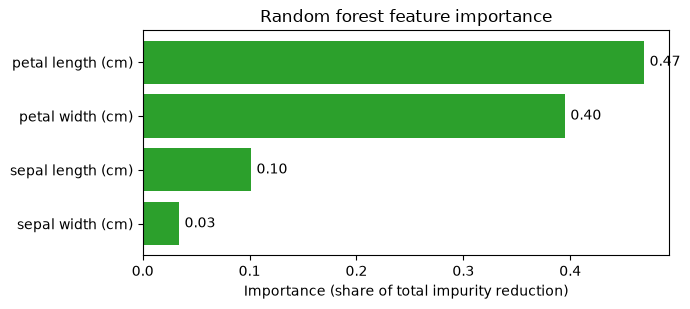

In [42]:
importances = pd.Series(rf.feature_importances_, index=iris.feature_names).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(importances.index, importances.values, color='tab:green')
for i, v in enumerate(importances.values):
    ax.text(v + 0.005, i, f'{v:.2f}', va='center')
ax.set_xlabel('Importance (share of total impurity reduction)')
ax.set_title('Random forest feature importance')
plt.tight_layout()
plt.show()

The petal measurements dominate, which matches the scatter plots from Part 0. The sepal measurements still get some credit, because Step 2 sometimes forced trees to use them.


## Part 7: Comparing the Models

### Scorecard

In [43]:
results = pd.DataFrame({
    'Model': ['Small tree (3 leaves)', 'Fully grown tree', 'Hand-built forest (25 trees)', 'scikit-learn forest (100 trees)'],
    'Test accuracy': [small_tree_acc,
                      full_tree.score(X_test, y_test),
                      my_forest_acc,
                      metrics.accuracy_score(y_test, rf_pred)],
    'Mistakes': [(y_pred != y_test).sum(),
                 (full_tree.predict(X_test) != y_test).sum(),
                 (my_forest_pred != y_test).sum(),
                 (rf_pred != y_test).sum()],
}).set_index('Model')
results.round(3)

,Test accuracy,Mistakes
Model,,
Small tree (3 leaves),0.895,4
Fully grown tree,0.974,1
Hand-built forest (25 trees),0.974,1
scikit-learn forest (100 trees),0.974,1


On iris, the fully grown tree and the forests make about the same number of mistakes on this test set. That's not surprising: iris is an easy dataset, and with only 38 test flowers there is very little room to show a difference. The real advantages of the forest show up when we look at **many** different splits, and when we look at **what the models believe** about every possible flower.

### Was this split typical? Repeat the experiment 30 times

We redo the whole experiment with 30 different random train/test splits and look at the spread of test accuracies.

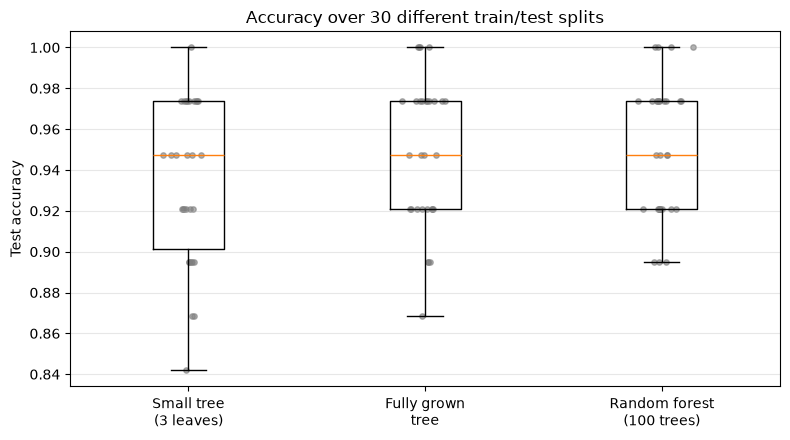

Small tree (3 leaves)        average = 0.934   lowest = 0.842
Fully grown tree             average = 0.948   lowest = 0.868
Random forest (100 trees)    average = 0.950   lowest = 0.895


In [44]:
model_makers = {
    'Small tree\n(3 leaves)': lambda: DecisionTreeClassifier(max_leaf_nodes=3, random_state=0),
    'Fully grown\ntree': lambda: DecisionTreeClassifier(random_state=0),
    'Random forest\n(100 trees)': lambda: RandomForestClassifier(n_estimators=100, random_state=0),
}
repeat_results = {name: [] for name in model_makers}
for seed in range(30):
    Xtr, Xte, ytr, yte = train_test_split(X, y, random_state=seed)
    for name, make in model_makers.items():
        repeat_results[name].append(make().fit(Xtr, ytr).score(Xte, yte))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(list(repeat_results.values()))
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(list(repeat_results.keys()))
for i, scores in enumerate(repeat_results.values(), start=1):
    ax.scatter(np.random.default_rng(i).normal(i, 0.04, len(scores)), scores, color='tab:gray', alpha=0.6, s=15)
ax.set_ylabel('Test accuracy')
ax.set_title('Accuracy over 30 different train/test splits')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

for name, scores in repeat_results.items():
    print(f"{name.replace(chr(10), ' '):<28} average = {np.mean(scores):.3f}   lowest = {np.min(scores):.3f}")

Each box shows the middle half of the 30 results, and the line inside it is the median. Compare the typical accuracy and the worst-case accuracy of each model. On an easy dataset like iris the differences are small; on harder data, such as the diabetes data in Example 1, the gap between a single tree and a forest is usually larger.

### What each model "believes": decision maps

Finally, let's train each model on just the **two petal measurements** so that we can draw a map of its predictions. Each point on the map is colored by the predicted probabilities: pure orange, green, or purple means the model is completely sure, and **blended colors** mean the model is unsure between species. The dots are the test flowers.

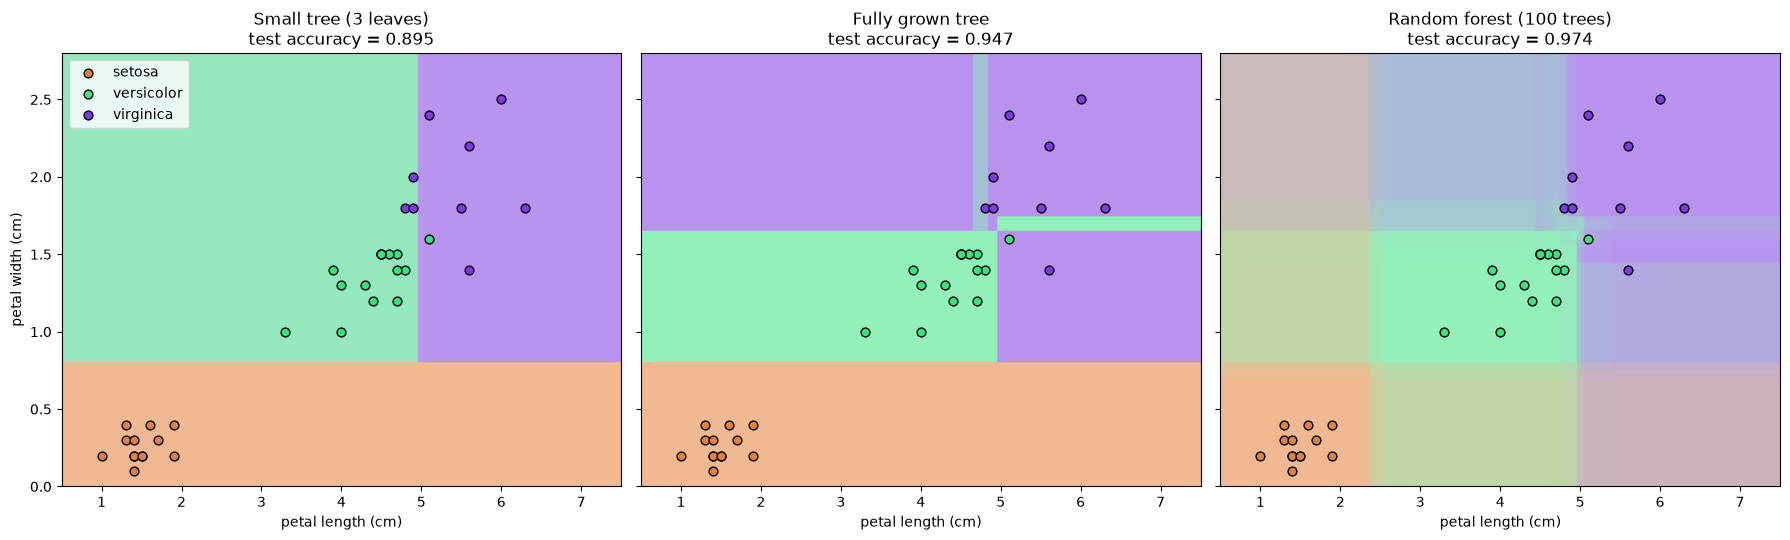

In [45]:
petal_cols = [PL, PW]
models_2d = {
    'Small tree (3 leaves)': DecisionTreeClassifier(max_leaf_nodes=3, random_state=0),
    'Fully grown tree': DecisionTreeClassifier(random_state=0),
    'Random forest (100 trees)': RandomForestClassifier(n_estimators=100, random_state=0),
}
grid_2d = np.c_[pl_grid.ravel(), pw_grid.ravel()]
from matplotlib.colors import to_rgb
rgb = np.array([to_rgb(c) for c in SPECIES_COLORS])   # each species color as (red, green, blue)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, (name, m) in zip(axes, models_2d.items()):
    m.fit(X_train[:, petal_cols], y_train)
    probs = m.predict_proba(grid_2d)                       # one probability per species
    image = (probs @ rgb).reshape(pl_grid.shape + (3,))    # blend the species colors
    image = 0.55 * image + 0.45                            # lighten so the dots stand out
    ax.imshow(image, origin='lower', aspect='auto',
              extent=[pl_grid.min(), pl_grid.max(), pw_grid.min(), pw_grid.max()])
    for k, species in enumerate(iris.target_names):
        ax.scatter(X_test[y_test == k, PL], X_test[y_test == k, PW], color=SPECIES_COLORS[k],
                   edgecolor='k', s=40, label=species)
    acc = m.score(X_test[:, petal_cols], y_test)
    ax.set_title(f'{name}\ntest accuracy = {acc:.3f}')
    ax.set_xlabel('petal length (cm)')
axes[0].set_ylabel('petal width (cm)')
axes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()

**What to notice:**

* The **small tree** divides the map into 3 rectangles. Its colors are slightly blended because its leaves contain a mix of species, but every flower in a rectangle gets the same answer.
* The **fully grown tree** is completely sure everywhere (no blending at all) and has thin strips and small boxes that exist only to handle one or two training flowers. That is overfitting made visible.
* The **random forest** averages 100 different trees. It is confident where the training flowers clearly belong to one species, and **blended** along the border where *versicolor* and *virginica* overlap. It honestly shows where the hard cases are.
* Look also at the **empty corners** of the forest's map, such as the top-left, where no real flower lives. There the trees disagree with each other, so the colors mix into a muddy blend. The forest is effectively saying *"I have never seen a flower like this."* The single trees, in contrast, confidently predict a species even there.


## Summary

**How a decision tree is stored**

* Every node has an ID number; node 0 is the root.
* `tree_` holds parallel lists: `children_left`, `children_right`, `feature`, `threshold` (plus `n_node_samples` and `value`). Position `i` in each list describes node `i`, and `-1` in the children lists marks a leaf.
* `decision_path` tells us every node a flower passes through; `apply` tells us the leaf where it ends.

**Why one tree isn't enough**

* Fully grown trees **memorize** the training data (overfitting).
* Small changes in the data can produce a different tree (**instability**).

**Random forest**

* A forest is just a **list of decision trees** (`rf.estimators_`), each with its own `tree_` arrays.
* Two kinds of randomness make the trees different: each tree gets a **bootstrap sample** of the rows, and each question may only use a **random few features**.
* The forest predicts the class with the **most votes**. The share of votes also tells us how **confident** it is.
* The trade-off: a forest is more stable and gives better-calibrated confidence, but 100 trees are much harder to explain than one small tree.

**Vocabulary:** node, root, leaf, node ID, threshold, parallel arrays, decision path, Gini impurity, overfitting, instability, bootstrap sample, out-of-bag, random feature subset, voting, ensemble, confusion matrix, feature importance.
